In [ ]:
w = 1
accuracies = [0.01680585287123032
0.036913602084535584
0.2552506625927777
0.08323779860133004
0.011659016790416124]
efficiencies = [0.999944025552706
0.6547174326995192
0.9999999771746891
0.9999999837026602
0.6935844690441394]

w = 2
accuracies = [0.13817536166278777
0.04329985049565666
0.34987209643159206
0.08374080502371832
0.015408690911825307]
efficiencies = [0.9998028544294404
0.7598910771826914
0.9999999434741518
0.9999999837573637
0.7758890047927864]


w = 4
accuracies = [0.16368711293683852
0.09424539531743635
0.11598650831837867
0.05318597088650306
0.003962791012811817]
efficiencies = [0.9992074480744415
0.7594604500179601
0.9999997570429869
0.9999916009511118
0.8440050375878001]

w = 8
accuracies = [0.16992925029131684
0.08704531057113717
0.04784562872613997
0.03262199783024673
0.0008228374713263603]
efficiencies = [0.9964305850244153
0.7557492996253483
0.9999986839053367
0.999948793672041
0.851997657593216]

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3124988410.py, line 2)

In [18]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target,SLMphaseRetrievalCG3D
from src.utils import phase_pbb_10,bottle_beam_phase
import torch
import matplotlib.pyplot as plt
import numpy as np
%load_ext autoreload
%autoreload 2

/Users/apple/anaconda3/envs/slm/lib/python3.13/site-packages/slmsuite/holography/algorithms/_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [120]:
import pandas as pd
from IPython.display import HTML

# Updated data for each radius
radii = [1, 2, 4, 8]
methods = ['Φgs','Φmraf','Φot','Φotgs','Φotmraf']

accuracies_list = [
    [0.01680585287123032, 0.036913602084535584, 0.2552506625927777, 0.08323779860133004, 0.011659016790416124],
    [0.13817536166278777, 0.04329985049565666, 0.34987209643159206, 0.08374080502371832, 0.015408690911825307],
    [0.16368711293683852, 0.09424539531743635, 0.11598650831837867, 0.05318597088650306, 0.003962791012811817],
    [0.16992925029131684, 0.08704531057113717, 0.04784562872613997, 0.03262199783024673, 0.0008228374713263603]
]

efficiencies_list = [
    [0.999944025552706, 0.6547174326995192, 0.9999999771746891, 0.9999999837026602, 0.6935844690441394],
    [0.9998028544294404, 0.7598910771826914, 0.9999999434741518, 0.9999999837573637, 0.7758890047927864],
    [0.9992074480744415, 0.7594604500179601, 0.9999997570429869, 0.9999916009511118, 0.8440050375878001],
    [0.9964305850244153, 0.7557492996253483, 0.9999986839053367, 0.999948793672041, 0.851997657593216]
]

# Build DataFrame
rows = []
for r, accs, effs in zip(radii, accuracies_list, efficiencies_list):
    for method, acc, eff in zip(methods, accs, effs):
        rows.append({'radius': r, 'method': method, 'rms error': acc, 'efficiency': eff})

df = pd.DataFrame(rows)

# Generate HTML for side-by-side tables with "radius =" header
html = '<div style="display: flex; gap: 20px;">'
for r in radii:
    subdf = df[df['radius'] == r].drop(columns='radius').reset_index(drop=True)
    table_html = subdf.to_html(index=False)
    html += f'''
    <div style="border:1px solid #ccc; padding:10px;">
      <h3 style="text-align:center;">radius = {r}</h3>
      {table_html}
    </div>
    '''
html += '</div>'

# Display the combined HTML
display(HTML(html))


method,rms error,efficiency
Φgs,0.016806,0.999944
Φmraf,0.036914,0.654717
Φot,0.255251,1.000000
Φotgs,0.083238,1.000000
Φotmraf,0.011659,0.693584
method,rms error,efficiency
Φgs,0.138175,0.999803
Φmraf,0.043300,0.759891
Φot,0.349872,1.000000
Φotgs,0.083741,1.000000


In [116]:
desired = ["Φgs", "Φmraf", "Φot", "Φotgs", "Φotmraf"]
import numpy as np
ws = 2
# 1) Load the archive
data = np.load(f"../SLMTools/examples/fields/fields_w{ws}.npz")

# 2) See what raw keys were stored
raw_keys = list(data.files)
print("raw keys:", raw_keys)

# 3) Build a mapping from raw→desired
desired = ["Φgs", "Φmraf", "Φot", "Φotgs", "Φotmraf"]
if len(raw_keys) != len(desired):
    raise ValueError("Unexpected number of keys in .npz")

mapping = dict(zip(raw_keys, desired))

# 4) Repackage into a clean dict
fields = { new_name: data[old_key] 
           for old_key, new_name in mapping.items() }

# 5) Now you can refer to them by the nice names:
phi_gs     = fields["Φgs"]
phi_mraf   = fields["Φmraf"]
phi_ot     = fields["Φot"]
phi_otgs   = fields["Φotgs"]
phi_otmraf = fields["Φotmraf"]

# Verify
for name, arr in fields.items():
    print(f"{name}: shape={arr.shape}, dtype={arr.dtype}")


raw keys: ['╬ªmraf', '╬ªgs', '╬ªotgs', '╬ªotmraf', '╬ªot']
Φgs: shape=(128, 128), dtype=complex128
Φmraf: shape=(128, 128), dtype=complex128
Φot: shape=(128, 128), dtype=complex128
Φotgs: shape=(128, 128), dtype=complex128
Φotmraf: shape=(128, 128), dtype=float64


In [121]:
H = 128
W = 128
pad_factor = 4
A_input = build_input(H = H, W = W,width = 32) 
m3d = SLMphaseRetrievalCG3D(A_in = A_input,A_t = None,pad_factor=pad_factor,H = H, W = W)

/Users/apple/Desktop/holography/src/gradient.py:128: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_in = self.pad(torch.tensor(A_in / FeedbackHologram._norm(A_in), dtype=torch.float32))


In [122]:
targ2 = m3d.build_target_from_phase(torch.angle(torch.tensor(phi_ot)))

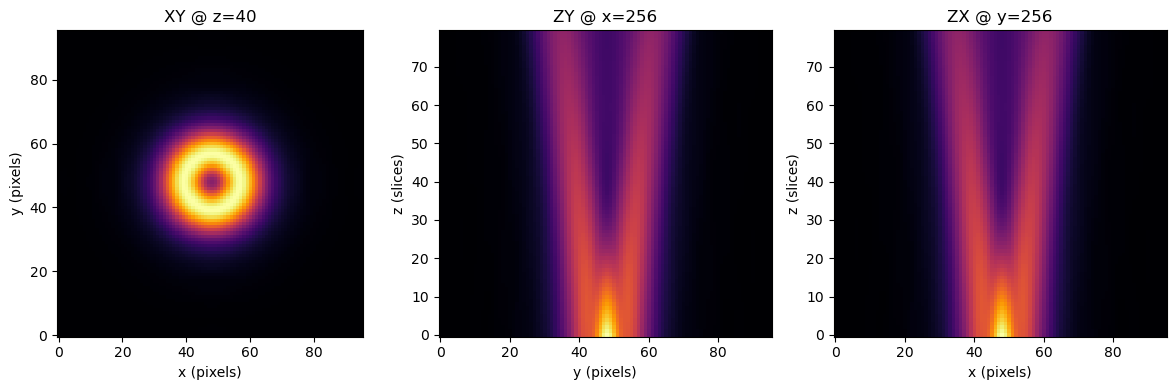

In [123]:
import matplotlib.pyplot as plt

# assume targ2 is a NumPy array (Z, Y, X)
# ws and pad_factor are defined
halfwin = int(6 * ws * pad_factor)
center = 64 * pad_factor
z_slice = targ2.shape[0]//2  # same plane you used for XY

# crop ranges
y0, y1 = center - halfwin, center + halfwin
x0, x1 = center - halfwin, center + halfwin

# 1) XY plane at z = z_slice
xy = targ2[z_slice, y0:y1, x0:x1]

# 2) ZY plane at x = center
#    shape: (Z, width_y)
zy = targ2[:, y0:y1, center]

# 3) ZX plane at y = center
#    shape: (Z, width_x)
zx = targ2[:, center, x0:x1]

# now plot
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# XY
axes[0].imshow(xy, origin='lower', cmap='inferno', aspect='equal')
axes[0].set_title(f'XY @ z={z_slice}')
axes[0].set_xlabel('x (pixels)')
axes[0].set_ylabel('y (pixels)')

# ZY
im1 = axes[1].imshow(zy, origin='lower', cmap='inferno', aspect='auto')
axes[1].set_title(f'ZY @ x={center}')
axes[1].set_xlabel('y (pixels)')
axes[1].set_ylabel('z (slices)')

# ZX
axes[2].imshow(zx, origin='lower', cmap='inferno', aspect='auto')
axes[2].set_title(f'ZX @ y={center}')
axes[2].set_xlabel('x (pixels)')
axes[2].set_ylabel('z (slices)')

plt.tight_layout()
plt.show()
